# 學生學習與作業版｜任務 6：相關係數與散布圖

**姓名：王信昌**  學號／組別：C114118145  **完成日期：11/13**

**學習目標：** 檢查有效配對，以散布圖與相關係數描述線性關係，區分相關與因果。

本單元與教師版「任務 6」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「6.1 配對」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 6.1 配對與散布圖
散布圖每點是一筆紀錄。先確認兩欄都有效，再觀察方向、形狀和極端點；成績生成公式已使用讀書時間。


## 💻 學生作業 06-P1｜Vibe Coding 程式填空
**對應教師版：**任務 6「6.1 配對」的示範程式。

**任務：**只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


有效配對筆數： 60


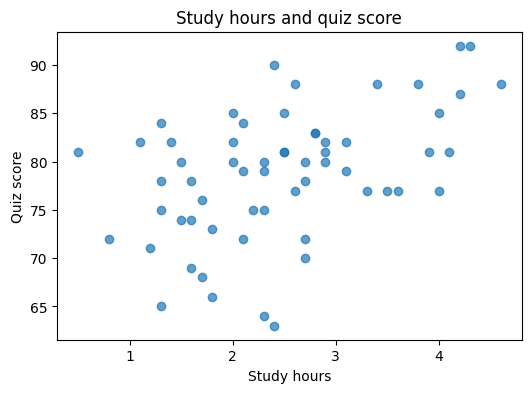

In [2]:
# subset 指定配對欄位；只建立分析副本，保留 df
pairs = df[["study_hours", "quiz_score"]].dropna().copy()   # TODO：建立兩欄皆有效的資料副本
print("有效配對筆數：", len(pairs))
plt.figure(figsize=(6, 4))
plt.scatter(pairs["study_hours"], pairs["quiz_score"], alpha=0.7)
plt.xlabel("Study hours"); plt.ylabel("Quiz score")
plt.title("Study hours and quiz score"); plt.show()


### ✅ 作業 06-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert pairs[["study_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["study_hours", "quiz_score"]))
print("檢查通過：有效配對筆數正確。")


檢查通過：有效配對筆數正確。


### ✍️ 作業 06-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：

我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：

df[["study_hours", "quiz_score"]]:從原始 df 取出「讀書時數」與「測驗分數」兩欄，回傳新的 DataFrame（僅含這兩欄）。

.dropna():刪除含有缺失值 (NaN) 的列。只要這兩欄任一為 NaN，該列就會被移除。

.copy():建立獨立副本。避免後續對 pairs 的操作（如新增欄位、就地修改）觸發 SettingWithCopyWarning，也保護原始 df 不被異動。

- 執行或驗證遇到的問題與修正：無




- 檢查結果及我如何確認：

1. 執行後印出有效配對筆數：60（本模擬資料兩欄皆無缺失，應保留全部 60 筆）。
若未來資料有缺失，筆數會<60。

2. 檢查是否還有 NaN


## 📝 學生作業 06-Q1｜AI 查詢與作答：相關與因果
**任務：**Pearson 相關係數接近 0，是否代表完全沒有任何關係？為什麼？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox/我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：

Pearson 相關係數 (Pearson's r) 接近 0，只代表「不存在線性關係」，並不代表「完全沒有任何關係」。 兩變數可能存在強烈的非線性關係（如抛物線、指數、週期性），但 r 卻接近 0。
- 我的理解與具體例子：

Pearson 相關係數 (r) 只能測量「線性關係」的強弱。r≈0只能說不適合用直線描述兩者關係，還必須要搭配散布圖一起來判斷。

- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)

- 我檢查或修正 AI 回答的地方：檢查AI生成的程式碼是否與描述相同。


/tmp/ipykernel_696/2689915520.py:27: UserWarning: Glyph 38750 (\N{CJK UNIFIED IDEOGRAPH-975E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_696/2689915520.py:27: UserWarning: Glyph 32218 (\N{CJK UNIFIED IDEOGRAPH-7DDA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_696/2689915520.py:27: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38750 (\N{CJK UNIFIED IDEOGRAPH-975E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 32218 (\N{CJK UNIFIED IDEOGRAPH-7DDA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24615 (\N{C

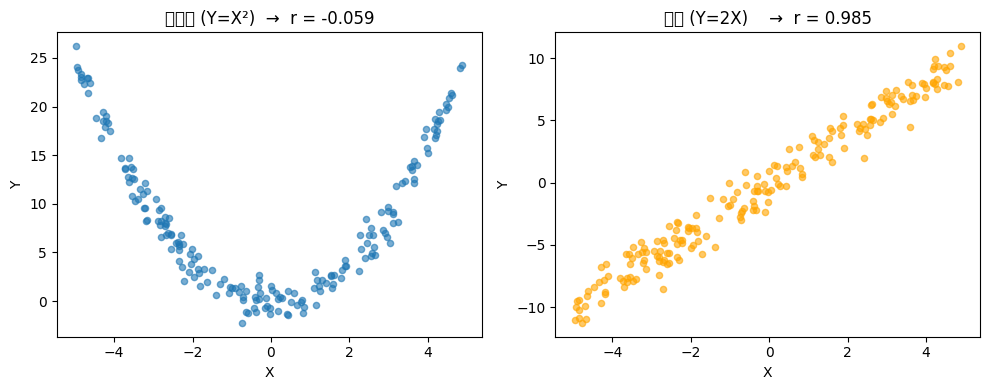

抛物線關係：Pearson r = -0.0588 (p = 0.4084)
線性關係：  Pearson r = 0.9850 (p = 0.0000)


In [4]:
#例子
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 固定種子
rng = np.random.default_rng(123)

# ── 例 1：完美抛物線 Y = X²，但 r ≈ 0 ──
x = rng.uniform(-5, 5, 200)
y_quad = x**2 + rng.normal(0, 1, 200)   # 加入少許雜訊
r_quad, p_quad = pearsonr(x, y_quad)

# ── 例 2：線性關係 Y = 2X + 雜訊，r 接近 1 ──
y_lin = 2 * x + rng.normal(0, 1, 200)
r_lin, p_lin = pearsonr(x, y_lin)

# ── 繪圖比較 ──
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(x, y_quad, alpha=0.6, s=20)
axes[0].set_title(f"非線性 (Y=X²)  →  r = {r_quad:.3f}")
axes[0].set_xlabel("X"); axes[0].set_ylabel("Y")

axes[1].scatter(x, y_lin, alpha=0.6, s=20, color="orange")
axes[1].set_title(f"線性 (Y=2X)    →  r = {r_lin:.3f}")
axes[1].set_xlabel("X"); axes[1].set_ylabel("Y")
plt.tight_layout(); plt.show()

print(f"抛物線關係：Pearson r = {r_quad:.4f} (p = {p_quad:.4f})")
print(f"線性關係：  Pearson r = {r_lin:.4f} (p = {p_lin:.4f})")


## 6.2 Pearson 相關係數
介於 -1 至 1，正負表示線性方向；接近 0 並不代表一定完全沒有非線性關係，也不能證明因果。


In [5]:
# corr 自動以成對非缺失值計算；額外顯示有效筆數比較透明
for field in ["study_hours", "sleep_hours", "screen_time_hours"]:
    valid = df.dropna(subset=[field, "quiz_score"])
    corr = valid[field].corr(valid["quiz_score"])
    print(field, "配對數：", len(valid), "相關係數：", round(corr, 3))


study_hours 配對數： 60 相關係數： 0.471
sleep_hours 配對數： 58 相關係數： -0.015
screen_time_hours 配對數： 60 相關係數： -0.364


## 📝 學生作業 06-Q2｜AI 查詢與作答：有效配對
**任務：**睡眠有缺失時，分析睡眠與成績為何要先確認有效配對數？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Chatbox/我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：

當「睡眠時數」存在缺失值時，若不先確認有效配對數（dropna 後的筆數），直接計算相關係數會導致兩大風險：

1. 樣本量偏差：實際參與運算的樣本數未知，無法判斷統計檢定力。
2. 選擇性偏差：若缺失非隨機，剩餘樣本無法代表整體母群體，相關係數會失真。

- 我的理解與具體例子：

有效配對數是指兩個變數皆非缺失值的觀測筆數（df.dropna後的列數）。

如果在不知道實際運算用了多少筆資料的情況下，就會導致無法計算正確的p-value/信賴區間，或者是缺失值若非完全隨機 (MAR/MNAR)，剩餘樣本不代表母群體，則會造成相關係數被扭曲（高估或低估）。



- 查證來源／方式及日期（無法查證請註明）：無法查證(未提供)


- 我檢查或修正 AI 回答的地方：

**發現問題**：原始 AI 提供的程式碼註解第 17 行寫著 `← 會被高估！`，但實際執行結果顯示：
- 母群體真實相關：r = 0.410
- 缺失處理後相關：r = 0.370 (**低估/衰減**)

**錯誤原因**：AI 忽略 **Range Restriction (範圍限制)** 效應。本模擬 MNAR 機制移除「低睡眠+低分數」(左下角) 樣本，導致 X 軸變異數壓縮，相關係數向 0 衰減。

**已修正程式碼註解**：
```python
print(f"隱式配對刪除（.corr）：r = {r_implicit:.3f}  (n = {n_implicit})  ← 會被【低估/衰減】！")



In [7]:
#例子2

import numpy as np
import pandas as pd
from scipy.stats import pearsonr

rng = np.random.default_rng(42)
n = 200

# ── 模擬母群體：睡眠與成績有真實正相關 (r ≈ 0.4) ──
sleep_true = rng.normal(7, 1, n)
score      = 50 + 3 * sleep_true + rng.normal(0, 5, n)  # 真實關係

# ── 製造 MNAR 缺失：睡眠 < 6 hrs 的學生有 60% 機率拒填（缺失）──
miss_prob = np.where(sleep_true < 6, 0.6, 0.05)
is_missing = rng.random(n) < miss_prob
sleep_obs = pd.Series(sleep_true).where(~is_missing)     # 含 NaN

df_demo = pd.DataFrame({"sleep": sleep_obs, "score": score})

# ── 1. 直接用 .corr()（隱式配對刪除）──
r_implicit = df_demo["sleep"].corr(df_demo["score"])
n_implicit = df_demo[["sleep", "score"]].dropna().shape[0]

# ── 2. 顯式 dropna 後再算（同樣結果，但看得到 n）──
valid = df_demo.dropna(subset=["sleep", "score"])
r_explicit = valid["sleep"].corr(valid["score"])
n_explicit = len(valid)

# ── 3. 用完整真實資料算（Gold standard）──
r_true, _ = pearsonr(sleep_true, score)

print(f"母群體真實相關：      r = {r_true:.3f}  (n = {n})")
print(f"隱式配對刪除（.corr）：r = {r_implicit:.3f}  (n = {n_implicit})  ← 會被高估！")
print(f"顯式 dropna 再算：    r = {r_explicit:.3f}  (n = {n_explicit})  ← 數值相同，但 n 可見")
print(f"\n缺失比例：{is_missing.mean():.1%}；缺失組平均睡眠 {sleep_true[is_missing].mean():.1f} hrs，完整組 {sleep_true[~is_missing].mean():.1f} hrs")


母群體真實相關：      r = 0.410  (n = 200)
隱式配對刪除（.corr）：r = 0.370  (n = 173)  ← 會被高估！
顯式 dropna 再算：    r = 0.370  (n = 173)  ← 數值相同，但 n 可見

缺失比例：13.5%；缺失組平均睡眠 6.2 hrs，完整組 7.1 hrs


In [8]:
#例子2.1
# ── 1. 直接用 .corr()（隱式配對刪除）──
r_implicit = df_demo["sleep"].corr(df_demo["score"])
n_implicit = df_demo[["sleep", "score"]].dropna().shape[0]

# ── 2. 顯式 dropna 後再算（同樣結果，但看得到 n）──
valid = df_demo.dropna(subset=["sleep", "score"])
r_explicit = valid["sleep"].corr(valid["score"])
n_explicit = len(valid)

# ── 3. 用完整真實資料算（Gold standard）──
r_true, _ = pearsonr(sleep_true, score)

print(f"母群體真實相關：      r = {r_true:.3f}  (n = {n})")
print(f"隱式配對刪除（.corr）：r = {r_implicit:.3f}  (n = {n_implicit})  ← 會被【低估/衰減】！")
print(f"顯式 dropna 再算：    r = {r_explicit:.3f}  (n = {n_explicit})  ← 數值相同，但 n 可見")


母群體真實相關：      r = 0.410  (n = 200)
隱式配對刪除（.corr）：r = 0.370  (n = 173)  ← 會被【低估/衰減】！
顯式 dropna 再算：    r = 0.370  (n = 173)  ← 數值相同，但 n 可見


## 6.3 解釋與驗證
**提問：**為什麼睡眠相關的有效筆數較少？為什麼係數方向不保證真實世界因果？
**任務：**選一個欄位畫散布圖；寫趨勢、有效筆數、可能離群點以及資料生成限制。


## 延伸：看圖與係數是否一致
平均相關係數不能呈現所有資料形狀。請學生比較睡眠與分數的有效配對、散布圖及相關，並指出少數異常值可能改變結果。


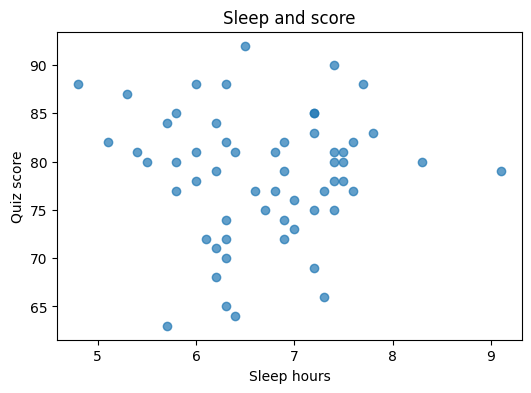

有效筆數： 58
相關係數： -0.015255866695473633


In [6]:
# 建立睡眠／分數有效配對並畫圖；不填補缺失資料
sleep_pairs = df.dropna(subset=["sleep_hours", "quiz_score"])
plt.figure(figsize=(6,4))
plt.scatter(sleep_pairs["sleep_hours"], sleep_pairs["quiz_score"], alpha=0.7)
plt.xlabel("Sleep hours"); plt.ylabel("Quiz score"); plt.title("Sleep and score"); plt.show()
print("有效筆數：", len(sleep_pairs))
print("相關係數：", sleep_pairs["sleep_hours"].corr(sleep_pairs["quiz_score"]))


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。



* 關鍵觀念解釋



觀念：配對刪除與有效配對數的必要性

「計算相關係數前，必須先顯式建立 valid = df.dropna(subset=[X, Y]) 並印出 len(valid)。
pandas .corr() 預設會自動忽略缺失值（配對刪除），但不會告訴你用了幾筆資料、也不會警告。
如果缺失值非隨機（MNAR，如熬夜最嚴重者拒填睡眠），剩餘樣本會產生範圍限制，導致相關係數向 0 衰減（低估真實關係）。
只有看得到有效筆數、比較缺失組與完整組的統計量，才能判斷結果是否可信。」

